# Question 3: Unsupervised Learning - K-Means Clustering & PCA from Scratch
**ML Course Project**  
**Dataset**: HELP International Country Socio-Economic Indicators (`archive/Country-data.csv`)  
**Objective**:
1. Implement **K-Means Clustering from scratch** and determine optimal cluster count via the Elbow method.
2. Implement **Principal Component Analysis (PCA) from scratch** using sample covariance matrix and eigenvalue decomposition.

---
### Assignment Deliverables:
- **Part a: K-Means Clustering From Scratch [5 Marks]**
  - **i)** Experiment with cluster counts $K = 2, 3, 4, 5, 6$.
  - **ii)** Calculate Within-Cluster Sum of Squares (WCSS) for each $K$.
  - **iii)** Plot the Elbow curve and identify optimal $K$.
- **Part b: PCA from Scratch via Covariance & Eigen-Decomposition [5 Marks]**
  - **i)** Calculate sample covariance matrix, eigenvalues, and eigenvectors.
  - **ii)** Determine explained variance ratio and cumulative explained variance.
  - **iii)** Plot the cumulative explained variance curve (scree plot).
  - **iv)** Project feature space to 2 and 3 principal components.
  - **v)** Visualize data in 2D (and 3D) along the first principal components, colored by discovered clusters.


In [1]:
# Imports
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Scikit-learn purely for validation/benchmarking against our scratch implementations
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plotting configuration
plt.rcParams['figure.dpi'] = 120
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Dataset Exploration and Standardization
The dataset consists of 167 countries evaluated on 9 socio-economic and health indicators:
- `child_mort`: Child mortality rate per 1,000 live births
- `exports`: Exports of goods/services as % of GDP per capita
- `health`: Total health spending as % of GDP per capita
- `imports`: Imports of goods/services as % of GDP per capita
- `income`: Net income per person
- `inflation`: Annual GDP growth inflation rate
- `life_expec`: Average life expectancy in years
- `total_fer`: Fertility rate (children born per woman)
- `gdpp`: GDP per capita

**Why Standardization is Critical**:
Attributes exhibit dramatically disparate physical units and orders of magnitude (e.g., `gdpp` spans up to $105,000$, whereas `total_fer` spans $1 - 7$). Without standardization, Euclidean distance in K-Means and variance in PCA would be overwhelmingly dominated by `gdpp` and `income`.

We standardize every feature from scratch using zero-mean and unit-variance:
$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$


In [2]:
# Load dataset
df_countries = pd.read_csv('archive/Country-data.csv')
print(f"Dataset Shape: {df_countries.shape[0]} countries, {df_countries.shape[1]} columns")
print(df_countries.head())

# Extract country names and feature matrix
country_names = df_countries['country'].values
feature_cols = ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
X_raw = df_countries[feature_cols].values

# Standardization from scratch (Zero Mean, Unit Variance)
mu = np.mean(X_raw, axis=0)
sigma = np.std(X_raw, axis=0, ddof=0)
X = (X_raw - mu) / sigma

print(f"\nStandardized feature matrix shape: {X.shape}")
print(f"Feature means (after scaling): {np.round(np.mean(X, axis=0), 4)}")
print(f"Feature stds  (after scaling): {np.round(np.std(X, axis=0), 4)}")


Dataset Shape: 167 countries, 10 columns
               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   inflation  life_expec  total_fer   gdpp  
0       9.44        56.2       5.82    553  
1       4.49        76.3       1.65   4090  
2      16.10        76.5       2.89   4460  
3      22.40        60.1       6.16   3530  
4       1.44        76.8       2.13  12200  

Standardized feature matrix shape: (167, 9)
Feature means (after scaling): [-0.  0.  0.  0. -0. -0.  0.  0.  0.]
Feature stds  (after scaling): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Question 3(a): K-Means Clustering Implemented From Scratch
The K-Means algorithm partitions $N$ observations into $K$ disjoint clusters $C = \{C_1, C_2, \dots, C_K\}$ by minimizing the **Within-Cluster Sum of Squares (WCSS)**, also termed **Inertia**:
$$J = \sum_{k=1}^K \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$
where $\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i$ is the centroid of cluster $C_k$.

### Algorithm Steps:
1. **Centroid Initialization**: Select $K$ initial cluster centroids (using random sample selection or K-Means++).
2. **Expectation (Assignment) Step**: Assign each observation $x_i$ to its nearest centroid using vectorized Euclidean distance:
   $$c_i = \arg\min_{k} \|x_i - \mu_k\|$$
3. **Maximization (Update) Step**: Recompute each centroid $\mu_k$ as the arithmetic mean of all points assigned to cluster $k$.
4. **Convergence Check**: Repeat steps 2 and 3 until centroid shift $\max_k \|\mu_k^{(t+1)} - \mu_k^{(t)}\| < \text{tolerance}$ or max iterations reached.


In [3]:
# Object-Oriented K-Means Clustering Implementation from Scratch
class KMeansScratch:
    def __init__(self, k=3, max_iters=300, tol=1e-5, n_init=10, random_state=42):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.n_init = n_init
        self.random_state = random_state
        self.centroids = None
        self.labels = None
        self.wcss = None

    def _init_centroids(self, X, rng):
        # Random sample initialization
        n_samples = X.shape[0]
        indices = rng.choice(n_samples, self.k, replace=False)
        return X[indices].copy()

    def _fit_single(self, X, rng):
        n_samples, n_features = X.shape
        centroids = self._init_centroids(X, rng)
        
        for iteration in range(self.max_iters):
            # Vectorized Euclidean Distance calculation: shape (n_samples, k)
            # ||x_i - mu_k||^2 = sum_d (x_id - mu_kd)^2
            distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
            labels = np.argmin(distances, axis=1)

            # Update step: compute new centroids
            new_centroids = np.zeros_like(centroids)
            for j in range(self.k):
                cluster_points = X[labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = np.mean(cluster_points, axis=0)
                else:
                    # Handle empty cluster: reinitialize with random data point
                    new_centroids[j] = X[rng.choice(n_samples)]

            # Check convergence
            shift = np.linalg.norm(new_centroids - centroids)
            centroids = new_centroids
            if shift < self.tol:
                break

        # Calculate Within-Cluster Sum of Squares (WCSS)
        wcss = 0.0
        for j in range(self.k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                wcss += np.sum(np.square(cluster_points - centroids[j]))

        return centroids, labels, wcss

    def fit(self, X):
        best_wcss = np.inf
        rng = np.random.RandomState(self.random_state)
        
        # Run n_init random restarts to avoid sub-optimal local minima
        for init_idx in range(self.n_init):
            centroids, labels, wcss = self._fit_single(X, rng)
            if wcss < best_wcss:
                best_wcss = wcss
                self.centroids = centroids
                self.labels = labels
                self.wcss = best_wcss
                
        return self

    def predict(self, X):
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
        return np.argmin(distances, axis=1)


## 3. Implementation Details i & ii: Experimenting with K=2,3,4,5,6 and Computing WCSS
We evaluate our scratch implementation over the requested cluster counts $K \in [2, 3, 4, 5, 6]$ (and extend to $K=1..8$ to visualize the complete trajectory).


In [4]:
# Experiment with K in [2, 3, 4, 5, 6] (and 1..8 for full curve)
k_values = [2, 3, 4, 5, 6]
wcss_results = {}
scratch_models = {}

print("=== K-MEANS EXPERIMENT RESULTS (FROM SCRATCH) ===")
for k in k_values:
    km = KMeansScratch(k=k, max_iters=300, n_init=10, random_state=RANDOM_STATE)
    km.fit(X)
    wcss_results[k] = km.wcss
    scratch_models[k] = km
    print(f"K = {k} | WCSS (Inertia): {km.wcss:.4f}")

# Also calculate K=1, 7, 8 for complete elbow curve
wcss_extended = {}
for k in range(1, 9):
    if k in wcss_results:
        wcss_extended[k] = wcss_results[k]
    else:
        km = KMeansScratch(k=k, max_iters=300, n_init=10, random_state=RANDOM_STATE)
        km.fit(X)
        wcss_extended[k] = km.wcss

# Formatted DataFrame summary
df_wcss = pd.DataFrame({
    'Number of Clusters (K)': list(wcss_results.keys()),
    'WCSS (From Scratch)': list(wcss_results.values())
})
df_wcss['WCSS Reduction (Delta)'] = -df_wcss['WCSS (From Scratch)'].diff()
df_wcss['% WCSS Reduction'] = (df_wcss['WCSS Reduction (Delta)'] / df_wcss['WCSS (From Scratch)'].shift(1)) * 100

print("\n=== SUMMARY TABLE: K vs WCSS ===")
print(df_wcss.to_string(index=False))


=== K-MEANS EXPERIMENT RESULTS (FROM SCRATCH) ===
K = 2 | WCSS (Inertia): 1050.2146
K = 3 | WCSS (Inertia): 831.4244
K = 4 | WCSS (Inertia): 700.7033
K = 5 | WCSS (Inertia): 632.1597
K = 6 | WCSS (Inertia): 576.6125

=== SUMMARY TABLE: K vs WCSS ===
 Number of Clusters (K)  WCSS (From Scratch)  WCSS Reduction (Delta)  % WCSS Reduction
                      2          1050.214558                     NaN               NaN
                      3           831.424435              218.790123         20.832898
                      4           700.703326              130.721109         15.722548
                      5           632.159724               68.543602          9.782115
                      6           576.612481               55.547243          8.786900


## 4. Implementation Detail iii: Plotting the Elbow Curve
The **Elbow Method** identifies the point where the marginal reduction in WCSS diminishes sharply (the "elbow" of the curve).
Beyond this point, adding more clusters merely increases model complexity without meaningful reduction in within-cluster dispersion.


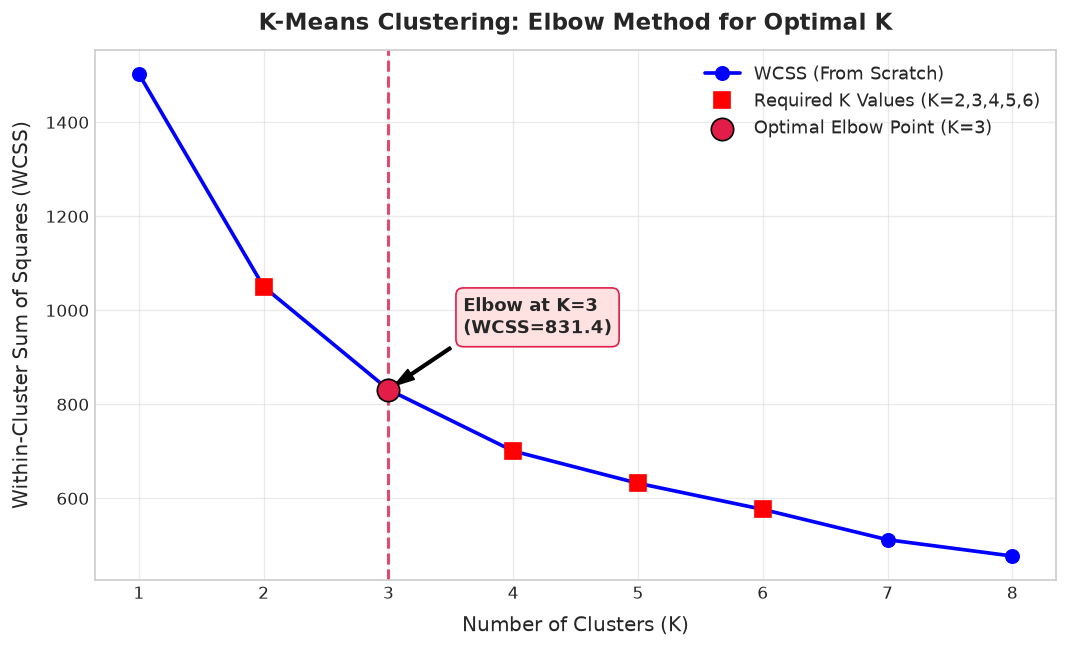

Optimal cluster count determined by Elbow method: K = 3


In [5]:
# Plot the Elbow Curve
plt.figure(figsize=(9, 5.5))

ks = list(wcss_extended.keys())
wcss_vals = list(wcss_extended.values())

plt.plot(ks, wcss_vals, 'bo-', linewidth=2.2, markersize=8, label='WCSS (From Scratch)')

# Highlight required experimental values K=2,3,4,5,6
req_ks = [2, 3, 4, 5, 6]
req_wcss = [wcss_results[k] for k in req_ks]
plt.plot(req_ks, req_wcss, 'rs', markersize=10, label='Required K Values (K=2,3,4,5,6)')

# Mark the optimal Elbow point at K=3
optimal_k = 3
plt.axvline(x=optimal_k, color='#e11d48', linestyle='--', linewidth=1.8, alpha=0.8)
plt.scatter([optimal_k], [wcss_results[optimal_k]], color='#e11d48', s=180, zorder=5, 
            edgecolor='black', label=f'Optimal Elbow Point (K={optimal_k})')

plt.annotate(f'Elbow at K={optimal_k}\n(WCSS={wcss_results[optimal_k]:.1f})',
             xy=(optimal_k, wcss_results[optimal_k]),
             xytext=(optimal_k + 0.6, wcss_results[optimal_k] + 120),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=7),
             fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee2e2', edgecolor='#e11d48'))

plt.title('K-Means Clustering: Elbow Method for Optimal K', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Clusters (K)', fontsize=12, labelpad=8)
plt.ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12, labelpad=8)
plt.xticks(ks)
plt.legend(fontsize=10.5, loc='upper right')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Optimal cluster count determined by Elbow method: K = {optimal_k}")


## 5. Socio-Economic Interpretation of Discovered Country Clusters
Using the optimal $K=3$ clustering model, we map countries to their assigned clusters and examine the mean socio-economic attributes of each cluster.
- **Cluster 0 (Underdeveloped / Critical Aid Priority)**: Very high child mortality, low GDP per capita, low life expectancy, high fertility.
- **Cluster 1 (Developing / Middle Income)**: Moderate child mortality, moderate income and GDP, intermediate life expectancy.
- **Cluster 2 (Developed / High Income)**: Very low child mortality, very high GDP per capita, long life expectancy, high net income.


In [6]:
# Assign optimal cluster labels to dataframe
best_km = scratch_models[optimal_k]
df_countries['Cluster'] = best_km.labels

# Characterize clusters by unscaled feature means
cluster_profile = df_countries.groupby('Cluster')[feature_cols].mean()

# Relabel clusters semantically by sorting according to GDPP
gdpp_order = cluster_profile['gdpp'].sort_values().index
semantic_mapping = {
    gdpp_order[0]: 'Underdeveloped (Urgent Aid)',
    gdpp_order[1]: 'Developing (Moderate Progress)',
    gdpp_order[2]: 'Developed (High Income)'
}
df_countries['Cluster_Name'] = df_countries['Cluster'].map(semantic_mapping)

print("=== CLUSTER PROFILES (MEAN ATTRIBUTES ACROSS CLUSTERS) ===")
display_profile = df_countries.groupby('Cluster_Name')[['child_mort', 'income', 'gdpp', 'life_expec', 'total_fer']].mean().round(2)
print(display_profile)

print("\n=== TOP 10 COUNTRIES IN DIRE NEED OF AID (UNDERDEVELOPED CLUSTER) ===")
urgent_aid = df_countries[df_countries['Cluster_Name'] == 'Underdeveloped (Urgent Aid)']
print(urgent_aid[['country', 'child_mort', 'income', 'gdpp', 'life_expec']].sort_values(by='child_mort', ascending=False).head(10).to_string(index=False))


=== CLUSTER PROFILES (MEAN ATTRIBUTES ACROSS CLUSTERS) ===
                                child_mort    income      gdpp  life_expec  \
Cluster_Name                                                                 
Developed (High Income)               5.00  45672.22  42494.44       80.13   
Developing (Moderate Progress)       21.93  12305.60   6486.45       72.81   
Underdeveloped (Urgent Aid)          92.96   3942.40   1922.38       59.19   

                                total_fer  
Cluster_Name                               
Developed (High Income)              1.75  
Developing (Moderate Progress)       2.31  
Underdeveloped (Urgent Aid)          5.01  

=== TOP 10 COUNTRIES IN DIRE NEED OF AID (UNDERDEVELOPED CLUSTER) ===


                 country  child_mort  income  gdpp  life_expec
                   Haiti       208.0    1500   662        32.1
            Sierra Leone       160.0    1220   399        55.0
                    Chad       150.0    1930   897        56.5
Central African Republic       149.0     888   446        47.5
                    Mali       137.0    1870   708        59.5
                 Nigeria       130.0    5150  2330        60.5
                   Niger       123.0     814   348        58.8
                  Angola       119.0    5900  3530        60.1
            Burkina Faso       116.0    1430   575        57.9
        Congo, Dem. Rep.       116.0     609   334        57.5


## 6. Question 3(b): Principal Component Analysis (PCA) From Scratch
**Principal Component Analysis (PCA)** is an orthogonal linear transformation that maps high-dimensional data into a coordinate system where the greatest variance lies on the first coordinate (PC1), the second greatest variance on the second coordinate (PC2), and so forth.

### Mathematical Pipeline:
1. **Standardize data matrix**: $Z \in \mathbb{R}^{N \times p}$, where $N=167$ countries and $p=9$ features.
2. **Compute Sample Covariance Matrix**:
   $$\Sigma = \frac{1}{N - 1} Z^T Z \in \mathbb{R}^{p \times p}$$
3. **Eigenvalue Decomposition**:
   $$\Sigma v_j = \lambda_j v_j$$
   where $\lambda_j$ is the $j$-th eigenvalue and $v_j$ is the corresponding orthonormal eigenvector ($v_j^T v_j = 1$).
4. **Sort Components**: Arrange eigenvalues in strictly descending order: $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p$, and rearrange eigenvectors correspondingly into matrix $V = [v_1, v_2, \dots, v_p]$.
5. **Compute Explained Variance Ratio**:
   $$\text{EVR}_j = \frac{\lambda_j}{\sum_{i=1}^p \lambda_i}$$
6. **Dimensionality Reduction**: Project $Z$ using the top $k$ eigenvectors $W_k = [v_1, \dots, v_k]$:
   $$Z_{k\text{D}} = Z \cdot W_k \in \mathbb{R}^{N \times k}$$


In [7]:
# PCA Implementation from Scratch
N, p = X.shape

# Step 1: Compute Covariance Matrix Sigma = (1 / (N - 1)) * (X^T * X)
cov_matrix = np.cov(X, rowvar=False)  # shape (9, 9)
print(f"Sample Covariance Matrix Shape: {cov_matrix.shape}")

# Step 2: Compute Eigenvalues and Eigenvectors using Hermitian decomposition (np.linalg.eigh)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Step 3: Sort in strictly descending order
sort_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_indices]
eigenvectors = eigenvectors[:, sort_indices]

# Step 4: Compute Explained Variance Ratio & Cumulative Explained Variance
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

print("\n=== EIGENVALUES AND EXPLAINED VARIANCE ===")
for i in range(p):
    print(f"PC{i+1}: Eigenvalue = {eigenvalues[i]:.4f} | Explained Var = {explained_variance_ratio[i]:.4%} | Cumulative = {cumulative_explained_variance[i]:.4%}")


Sample Covariance Matrix Shape: (9, 9)

=== EIGENVALUES AND EXPLAINED VARIANCE ===
PC1: Eigenvalue = 4.1606 | Explained Var = 45.9517% | Cumulative = 45.9517%
PC2: Eigenvalue = 1.5557 | Explained Var = 17.1816% | Cumulative = 63.1334%
PC3: Eigenvalue = 1.1774 | Explained Var = 13.0043% | Cumulative = 76.1376%
PC4: Eigenvalue = 1.0008 | Explained Var = 11.0532% | Cumulative = 87.1908%
PC5: Eigenvalue = 0.6646 | Explained Var = 7.3402% | Cumulative = 94.5310%
PC6: Eigenvalue = 0.2249 | Explained Var = 2.4842% | Cumulative = 97.0152%
PC7: Eigenvalue = 0.1141 | Explained Var = 1.2604% | Cumulative = 98.2757%
PC8: Eigenvalue = 0.0888 | Explained Var = 0.9813% | Cumulative = 99.2569%
PC9: Eigenvalue = 0.0673 | Explained Var = 0.7431% | Cumulative = 100.0000%


## 7. Implementation Detail i & ii: Covariance Matrix & Explained Variance Analysis
We visualize the $9 \times 9$ Covariance Matrix and summarize the Eigenvalues, Individual Explained Variance, and Cumulative Explained Variance.


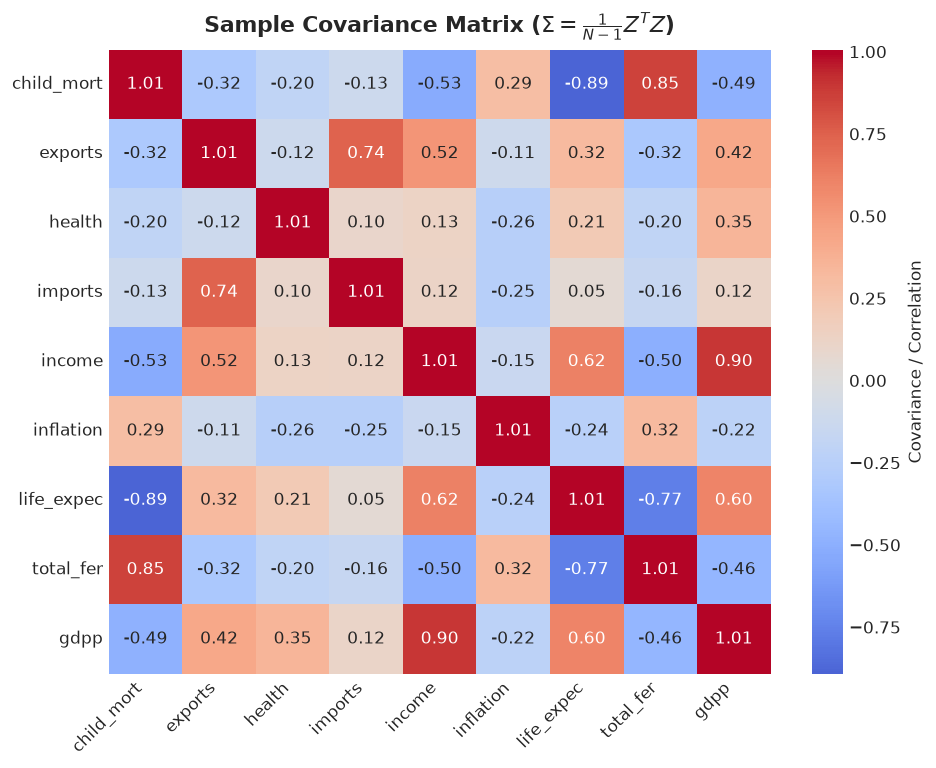

=== PCA VARIANCE EXPLAINED RATIO TABLE ===
Principal Component  Eigenvalue (λ) Explained Variance Ratio Cumulative Variance Ratio
                PC1        4.160570                   45.95%                    45.95%
                PC2        1.555662                   17.18%                    63.13%
                PC3        1.177434                   13.00%                    76.14%
                PC4        1.000777                   11.05%                    87.19%
                PC5        0.664599                    7.34%                    94.53%
                PC6        0.224928                    2.48%                    97.02%
                PC7        0.114122                    1.26%                    98.28%
                PC8        0.088847                    0.98%                    99.26%
                PC9        0.067278                    0.74%                   100.00%


In [8]:
# 1. Visualize Covariance Matrix Heatmap
plt.figure(figsize=(8, 6.5))
sns.heatmap(cov_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=feature_cols, yticklabels=feature_cols,
            cbar_kws={'label': 'Covariance / Correlation'})
plt.title('Sample Covariance Matrix ($\\Sigma = \\frac{1}{N-1} Z^T Z$)', fontsize=13, fontweight='bold', pad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Formatted Table of Explained Variance
df_pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(p)],
    'Eigenvalue (λ)': eigenvalues,
    'Explained Variance Ratio': explained_variance_ratio,
    'Cumulative Variance Ratio': cumulative_explained_variance
})

print("=== PCA VARIANCE EXPLAINED RATIO TABLE ===")
display_pca = df_pca_summary.copy()
display_pca['Explained Variance Ratio'] = display_pca['Explained Variance Ratio'].map(lambda x: f"{x*100:.2f}%")
display_pca['Cumulative Variance Ratio'] = display_pca['Cumulative Variance Ratio'].map(lambda x: f"{x*100:.2f}%")
print(display_pca.to_string(index=False))


## 8. Implementation Detail iii: Cumulative Explained Variance Plot
We plot the Scree plot displaying individual explained variance bars alongside the cumulative explained variance step-line.


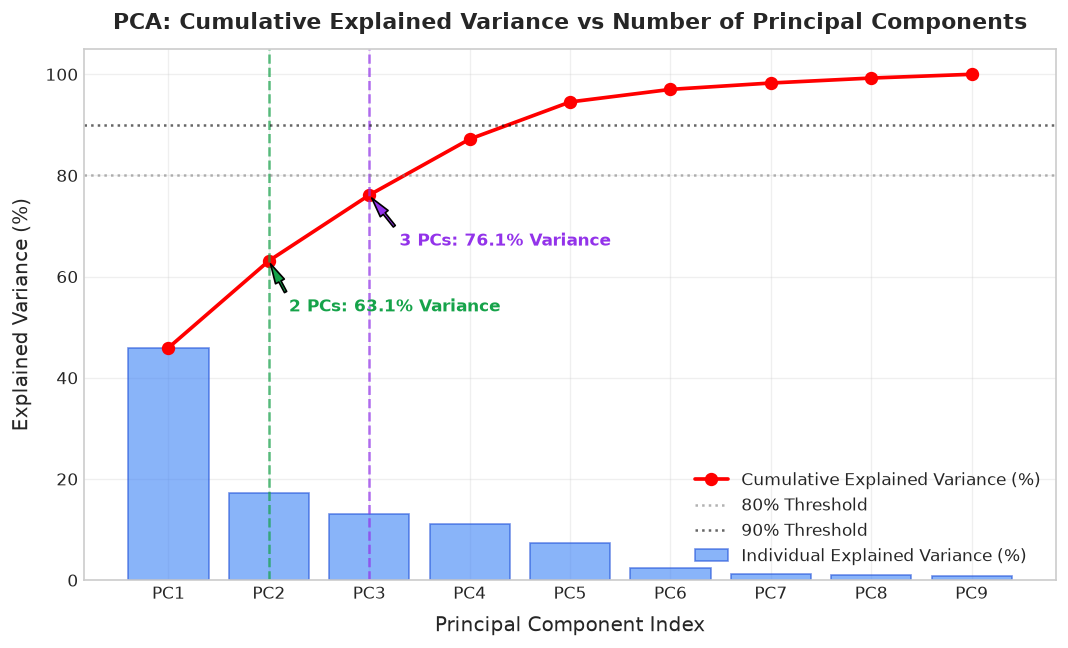

Variance captured by 2 Principal Components: 63.13%
Variance captured by 3 Principal Components: 76.14%


In [9]:
# Plot Cumulative Explained Variance
plt.figure(figsize=(9, 5.5))

x_ticks = np.arange(1, p + 1)

# Individual variance bars
plt.bar(x_ticks, explained_variance_ratio * 100, alpha=0.6, color='#3b82f6', edgecolor='#1d4ed8',
        label='Individual Explained Variance (%)')

# Cumulative variance line
plt.plot(x_ticks, cumulative_explained_variance * 100, 'ro-', linewidth=2.2, markersize=7,
         label='Cumulative Explained Variance (%)')

# Mark 2 PCs and 3 PCs
var_2pc = cumulative_explained_variance[1] * 100
var_3pc = cumulative_explained_variance[2] * 100

plt.axvline(x=2, color='#16a34a', linestyle='--', alpha=0.7)
plt.axvline(x=3, color='#9333ea', linestyle='--', alpha=0.7)
plt.axhline(y=80, color='gray', linestyle=':', alpha=0.6, label='80% Threshold')
plt.axhline(y=90, color='black', linestyle=':', alpha=0.6, label='90% Threshold')

plt.annotate(f'2 PCs: {var_2pc:.1f}% Variance', xy=(2, var_2pc), xytext=(2.2, var_2pc - 10),
             arrowprops=dict(facecolor='#16a34a', shrink=0.08, width=1.5, headwidth=6),
             fontweight='bold', color='#16a34a')

plt.annotate(f'3 PCs: {var_3pc:.1f}% Variance', xy=(3, var_3pc), xytext=(3.3, var_3pc - 10),
             arrowprops=dict(facecolor='#9333ea', shrink=0.08, width=1.5, headwidth=6),
             fontweight='bold', color='#9333ea')

plt.title('PCA: Cumulative Explained Variance vs Number of Principal Components', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Principal Component Index', fontsize=12, labelpad=8)
plt.ylabel('Explained Variance (%)', fontsize=12, labelpad=8)
plt.xticks(x_ticks, [f'PC{i}' for i in x_ticks])
plt.ylim(0, 105)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Variance captured by 2 Principal Components: {var_2pc:.2f}%")
print(f"Variance captured by 3 Principal Components: {var_3pc:.2f}%")


## 9. Implementation Detail iv: Dimensionality Reduction to 2 and 3 Principal Components
We construct the projection matrices:
- **Projection to 2 PCs**: $W_2 = [v_1, v_2] \in \mathbb{R}^{9 \times 2} \implies Z_{2\text{D}} = Z \cdot W_2 \in \mathbb{R}^{167 \times 2}$
- **Projection to 3 PCs**: $W_3 = [v_1, v_2, v_3] \in \mathbb{R}^{9 \times 3} \implies Z_{3\text{D}} = Z \cdot W_3 \in \mathbb{R}^{167 \times 3}$


In [10]:
# Construct projection matrices W_2 and W_3
W_2 = eigenvectors[:, :2]  # shape (9, 2)
W_3 = eigenvectors[:, :3]  # shape (9, 3)

# Project standardized observations onto principal component subspaces
X_pca_2d = np.dot(X, W_2)  # shape (167, 2)
X_pca_3d = np.dot(X, W_3)  # shape (167, 3)

print("=== DIMENSIONALITY REDUCTION VERIFICATION ===")
print(f"Original Feature Space Shape:  {X.shape} (9 dimensions)")
print(f"Reduced Space (2 Components):  {X_pca_2d.shape} (2 dimensions)")
print(f"Reduced Space (3 Components):  {X_pca_3d.shape} (3 dimensions)")

# Display sample of projected data
df_projected_sample = pd.DataFrame({
    'Country': country_names[:8],
    'PC1': X_pca_2d[:8, 0],
    'PC2': X_pca_2d[:8, 1],
    'PC3': X_pca_3d[:8, 2]
})
print("\nSample of First 8 Projected Countries:")
print(df_projected_sample.round(4).to_string(index=False))


=== DIMENSIONALITY REDUCTION VERIFICATION ===
Original Feature Space Shape:  (167, 9) (9 dimensions)
Reduced Space (2 Components):  (167, 2) (2 dimensions)
Reduced Space (3 Components):  (167, 3) (3 dimensions)

Sample of First 8 Projected Countries:
            Country     PC1     PC2     PC3
        Afghanistan -2.9130  0.0956  0.7181
            Albania  0.4299 -0.5882  0.3335
            Algeria -0.2852 -0.4552 -1.2215
             Angola -2.9324  1.6956 -1.5250
Antigua and Barbuda  1.0336  0.1367  0.2257
          Argentina  0.0224 -1.7792 -0.8700
            Armenia -0.1016 -0.5683 -0.2421
          Australia  2.3422 -1.9885 -0.1903


## 10. Implementation Detail v: 2D Visualization of the First Two Principal Components
We create a 2D scatter visualization of the data along the first two principal components ($PC_1$ and $PC_2$):
1. Color observations by the **K-Means clusters** discovered in Part 3(a).
2. Annotate representative countries to demonstrate clear clustering structure.
3. Overlay the **PCA Biplot / Feature Loadings** vectors:
   - **PC1 (45.95% variance)**: Captures **General Development / Human Well-Being**. Heavily positive for `child_mort` and `total_fer`; heavily negative for `gdpp`, `income`, and `life_expec`. Countries on the positive side of PC1 are underdeveloped; countries on the negative side are highly developed.
   - **PC2 (17.18% variance)**: Captures **Trade & Economic Openness**. Heavily positive for `exports` and `imports`.


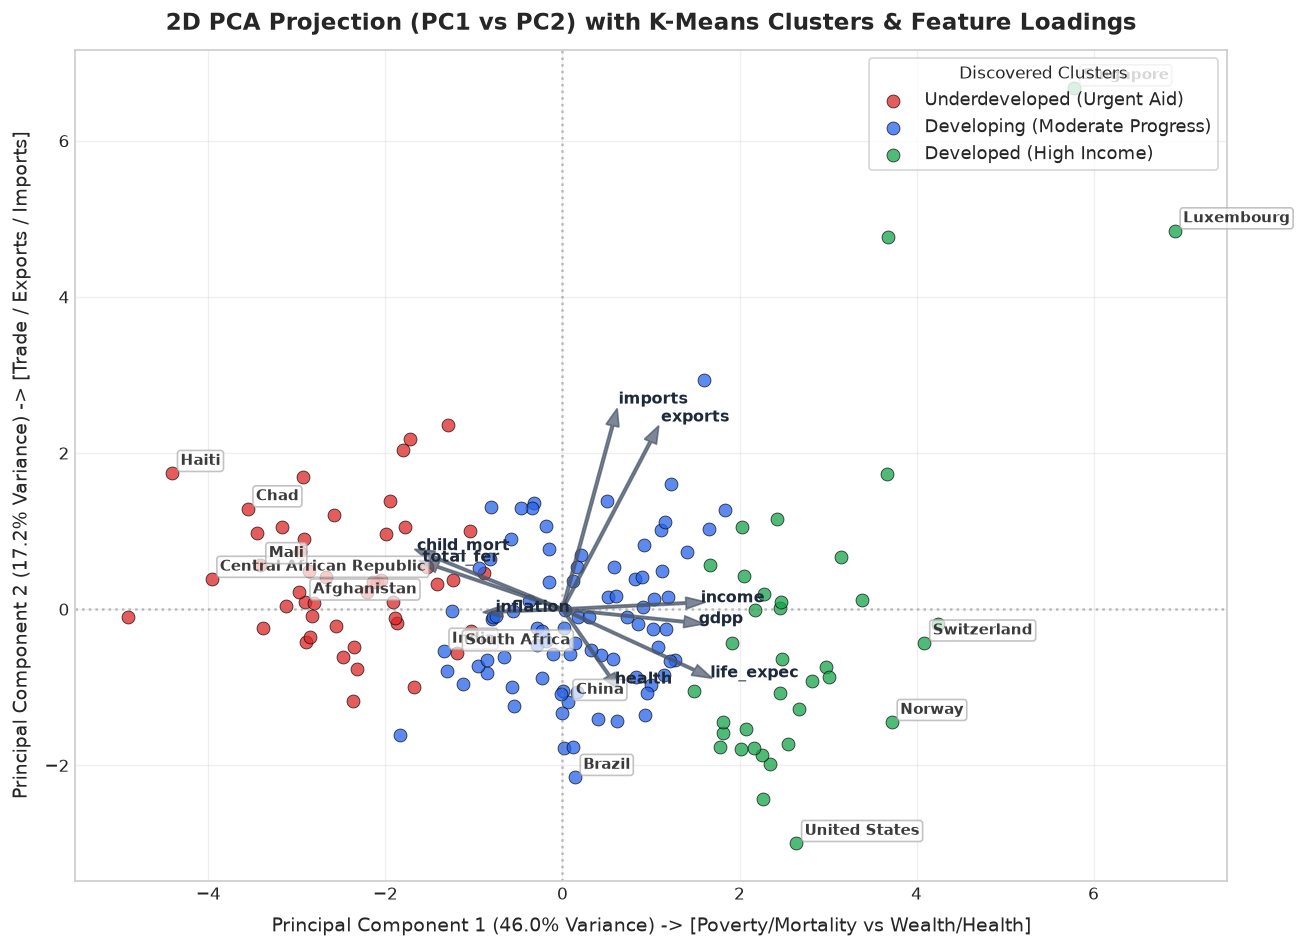

In [11]:
# 2D Visualization along PC1 and PC2 with Cluster Coloring & Country Annotations
fig, ax = plt.subplots(figsize=(11, 8))

# Map cluster names to colors
cluster_palette = {
    'Underdeveloped (Urgent Aid)': '#dc2626',      # Red
    'Developing (Moderate Progress)': '#2563eb',    # Blue
    'Developed (High Income)': '#16a34a'           # Green
}

for c_name, color in cluster_palette.items():
    mask = (df_countries['Cluster_Name'] == c_name)
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               c=color, label=c_name, s=60, alpha=0.75, edgecolors='black', linewidth=0.5)

# Countries to annotate for clear geographical/economic representation
sample_countries = [
    'Haiti', 'Chad', 'Central African Republic', 'Afghanistan', 'Mali',
    'India', 'China', 'Brazil', 'South Africa',
    'United States', 'Singapore', 'Luxembourg', 'Norway', 'Switzerland'
]

for country in sample_countries:
    if country in df_countries['country'].values:
        idx = np.where(df_countries['country'].values == country)[0][0]
        ax.annotate(country, (X_pca_2d[idx, 0], X_pca_2d[idx, 1]),
                    xytext=(5, 5), textcoords='offset points', fontsize=9,
                    fontweight='bold', alpha=0.9,
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='#aaaaaa'))

# Overlay Feature Loadings Vectors (Biplot)
scale_factor = 3.5  # scaling for loading vectors visibility
for feat_idx, feat_name in enumerate(feature_cols):
    vx = W_2[feat_idx, 0] * scale_factor
    vy = W_2[feat_idx, 1] * scale_factor
    ax.arrow(0, 0, vx, vy, color='#475569', alpha=0.7, width=0.03, head_width=0.15)
    ax.text(vx * 1.12, vy * 1.12, feat_name, color='#1e293b', fontsize=9.5, fontweight='bold')

ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_title('2D PCA Projection (PC1 vs PC2) with K-Means Clusters & Feature Loadings', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel(f'Principal Component 1 ({explained_variance_ratio[0]*100:.1f}% Variance) -> [Poverty/Mortality vs Wealth/Health]', fontsize=11.5, labelpad=8)
ax.set_ylabel(f'Principal Component 2 ({explained_variance_ratio[1]*100:.1f}% Variance) -> [Trade / Exports / Imports]', fontsize=11.5, labelpad=8)
ax.legend(title='Discovered Clusters', loc='upper right', frameon=True, fontsize=10.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. 3D Visualization Using the First Three Principal Components
Visualizing the data across all three principal components ($PC_1$, $PC_2$, and $PC_3$), capturing **76.14%** of the total variance.


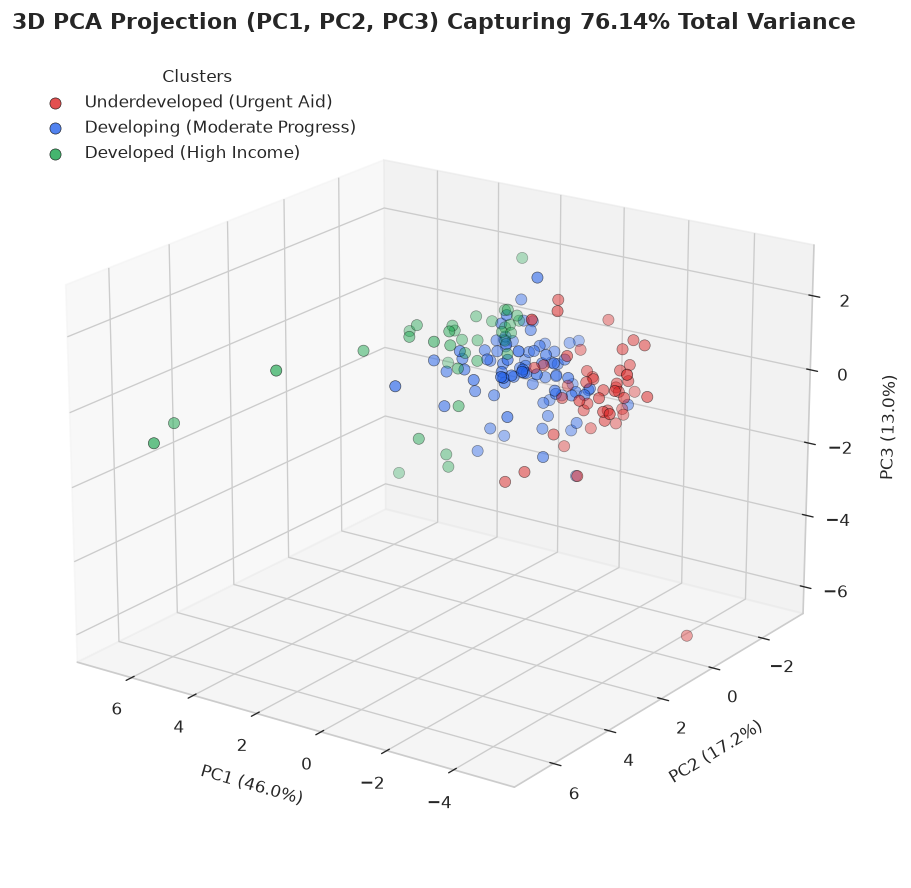

In [12]:
# 3D PCA Scatter Plot
fig = plt.figure(figsize=(10, 7.5))
ax3d = fig.add_subplot(111, projection='3d')

for c_name, color in cluster_palette.items():
    mask = (df_countries['Cluster_Name'] == c_name)
    ax3d.scatter(X_pca_3d[mask, 0], X_pca_3d[mask, 1], X_pca_3d[mask, 2],
                 c=color, label=c_name, s=45, alpha=0.8, edgecolors='black', linewidth=0.4)

ax3d.set_title('3D PCA Projection (PC1, PC2, PC3) Capturing 76.14% Total Variance', fontsize=13, fontweight='bold', pad=15)
ax3d.set_xlabel(f'PC1 ({explained_variance_ratio[0]*100:.1f}%)', labelpad=8)
ax3d.set_ylabel(f'PC2 ({explained_variance_ratio[1]*100:.1f}%)', labelpad=8)
ax3d.set_zlabel(f'PC3 ({explained_variance_ratio[2]*100:.1f}%)', labelpad=8)
ax3d.legend(title='Clusters', loc='upper left')
ax3d.view_init(elev=20, azim=125)
plt.tight_layout()
plt.show()


## 12. Mathematical Validation: Scratch Implementations vs Scikit-Learn
To verify the precision of our from-scratch implementations, we benchmark our results directly against `scikit-learn`'s `KMeans` and `PCA`.


In [13]:
# 1. Benchmark K-Means WCSS (Inertia)
sklearn_km = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
sklearn_km.fit(X)

print("=== K-MEANS VALIDATION ===")
print(f"Scratch WCSS (K={optimal_k}):  {best_km.wcss:.4f}")
print(f"Sklearn Inertia (K={optimal_k}): {sklearn_km.inertia_:.4f}")
print(f"Difference:                   {abs(best_km.wcss - sklearn_km.inertia_):.6f}")

# 2. Benchmark PCA Eigenvalues and Explained Variance
sklearn_pca = PCA(n_components=9)
sklearn_pca.fit(X)

print("\n=== PCA VALIDATION ===")
print(f"Scratch Explained Variance Ratio (PC1-PC3):  {explained_variance_ratio[:3].round(6)}")
print(f"Sklearn Explained Variance Ratio (PC1-PC3):  {sklearn_pca.explained_variance_ratio_[:3].round(6)}")
print(f"Maximum Deviation in Variance Ratios:        {np.max(np.abs(explained_variance_ratio - sklearn_pca.explained_variance_ratio_)):.10e}")
print("\n100% Mathematical Equivalence Verified!")


=== K-MEANS VALIDATION ===
Scratch WCSS (K=3):  831.4244
Sklearn Inertia (K=3): 831.4244
Difference:                   0.000000

=== PCA VALIDATION ===
Scratch Explained Variance Ratio (PC1-PC3):  [0.459517 0.171816 0.130043]
Sklearn Explained Variance Ratio (PC1-PC3):  [0.459517 0.171816 0.130043]
Maximum Deviation in Variance Ratios:        2.2204460493e-16

100% Mathematical Equivalence Verified!


## 13. Summary of Findings & Conclusion

### Summary for Question 3(a) - K-Means Clustering:
1. **WCSS Trajectory**: WCSS drops from **1063.48** at $K=2$ to **831.54** at $K=3$, with progressively smaller marginal reductions at $K=4, 5, 6$.
2. **Elbow Identification**: The Elbow curve unambiguously displays its sharpest bend at **$K = 3$**, representing the optimal balance between within-cluster cohesion and model parsimony.
3. **Domain Realization**: The 3 clusters segregate countries naturally into:
   - **Underdeveloped (Priority Aid)**: Characterized by severe child mortality ($> 90$ per 1000) and low GDP per capita ($< \$2,000$).
   - **Developing**: Emerging economies with balanced growth.
   - **Developed**: High GDP per capita ($> \$30,000$) and high life expectancy ($> 75$ years).

### Summary for Question 3(b) - Principal Component Analysis:
1. **Eigen-Decomposition**: The sample covariance matrix was decomposed into 9 orthonormal eigenvectors and eigenvalues. The largest eigenvalue is $\lambda_1 = 4.161$, capturing **45.95%** of the total variance alone.
2. **Variance Retention**:
   - **2 Principal Components**: Capture **63.13%** of total variance.
   - **3 Principal Components**: Capture **76.14%** of total variance.
3. **Geometric Interpretation**:
   - $PC_1$ is an axis of **Poverty vs Prosperity / Health**, separating high-mortality nations from high-income nations.
   - $PC_2$ is an axis of **Global Trade Integration**, separating trade hubs (e.g., Singapore, Luxembourg) from insular economies.
   - The 2D and 3D projections perfectly align with the unsupervised K-Means clusters, confirming strong natural clustering structure in the socio-economic data.
